In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from IPython.display import clear_output
import matplotlib.pyplot as plt

# Гречишкин Денис, ПМ-41
## Лабораторная работа №4
## Нейронные сети

## Цель работы:  подготовить модель типа U-net для решения задачи сегметнации изображений на основе предобученной сверточной сети, путем внедрения в ее структуру сквозных соединений между дальними слоями.

## Часть 1. Построение моделей со сквозными соединениями

# 1.1. Подготовка к работе.

In [ ]:
dataset, info = tfds.load('oxford_iiit_pet:4.*.*', with_info=True)
# загружаем набор изображений вместе с готовыми масками для обучения
TRAIN_LENGTH = info.splits['train'].num_examples
# набор данных уже размечен для валидации и обучения
BATCH_SIZE = 64 # можете установить 32 или 128, как вариант
BUFFER_SIZE = 1000 # размер буфера для перемешивания обучающих данных
STEPS_PER_EPOCH = TRAIN_LENGTH // BATCH_SIZE

def normalize(input_image, input_mask):
  input_image = tf.cast(input_image, tf.float32) / 255.0
  # значения пикселей для изображений отобразим на отрезок [0,1]
  input_mask-= 1 # значение пикселей для маски полагаем:-1, 0, 1
  return input_image, input_mask
def load_image(datapoint):
  input_image = tf.image.resize(datapoint['image'], (128, 128))
  input_mask = tf.image.resize(
  datapoint['segmentation_mask'],
  (128, 128),
  method = tf.image.ResizeMethod.NEAREST_NEIGHBOR,
  )
  input_image, input_mask = normalize(input_image, input_mask)
  return input_image, input_mask

train_images = dataset['train'].map(load_image,
num_parallel_calls=tf.data.AUTOTUNE)
test_images = dataset['test'].map(load_image,
num_parallel_calls=tf.data.AUTOTUNE)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.UTF6F4_4.0.0/oxford_iiit_pet-train.tfrecord*...…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.UTF6F4_4.0.0/oxford_iiit_pet-test.tfrecord*...:…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.


In [ ]:
class Augment(tf.keras.layers.Layer):
  def __init__(self, seed=42):
    super().__init__()
    self.augment_inputs = tf.keras.layers.RandomFlip(mode="horizontal",
    seed=seed)
    self.augment_labels = tf.keras.layers.RandomFlip(mode="horizontal",
    seed=seed)
  def call(self, inputs, labels):
    inputs = self.augment_inputs(inputs)
    labels = self.augment_labels(labels)
    return inputs, labels

# 1.2. Искуственное расширение обучающей выборки.

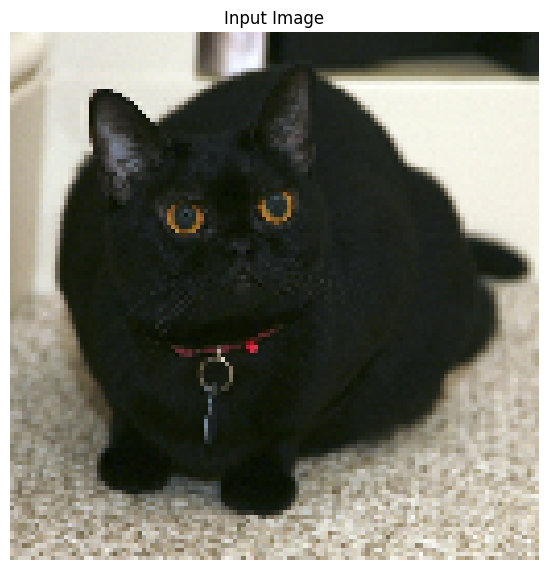

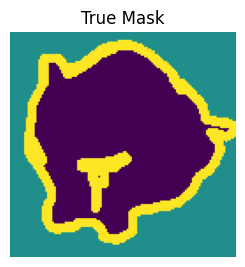

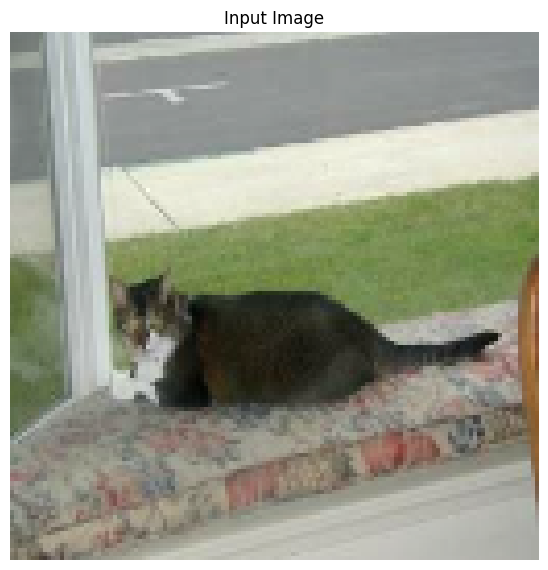

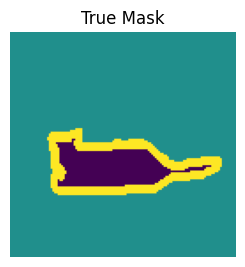

In [ ]:
train_batches = (
  train_images
  .cache()
  .shuffle(BUFFER_SIZE)
  .batch(BATCH_SIZE)
  .repeat()
  .map(Augment())
  .prefetch(buffer_size=tf.data.AUTOTUNE))
test_batches = test_images.batch(BATCH_SIZE)

def display(display_list):
  plt.figure(figsize=(15, 15))
  title = ['Input Image', 'True Mask', 'Predicted Mask']
  for i in range(len(display_list)):
    plt.subplot(1, len(display_list), i+1)
    plt.title(title[i])
    plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
    plt.axis('off')
    plt.show()

for images, masks in train_batches.take(2):
  sample_image, sample_mask = images[0], masks[0]
  display([sample_image, sample_mask])


# 1.3.  Перенос обучения с добавлением сквозных соединений.

In [ ]:
base_model = tf.keras.applications.MobileNetV2( input_shape=[128, 128, 3],
include_top=False)

layer_names = [
  'block_1_expand_relu',# 64x64 размерность
  'block_3_expand_relu',# 32x32 размерность
  'block_6_expand_relu',# 16x16 размерность
  'block_13_expand_relu', # 8x8 размерность
  'block_16_project',# 4x4 размерность
]

base_model_outputs =[base_model.get_layer(name).output for name in layer_names]
# Создаем энкодерную часть модели (downsampler):
down_stack = tf.keras.Model(inputs=base_model.input,
outputs=base_model_outputs)
down_stack.trainable = False
# замораживаем коэффициенты предобученной модели MobileNet2

def upsample(filters, size, apply_dropout=False):
  initializer = tf.random_normal_initializer(0., 0.02)
  # инициализатор с нормальным распределением (m=0, sigma=0.02)
  result = tf.keras.Sequential()
  result.add(tf.keras.layers.Conv2DTranspose(filters, size, strides=2,
  padding='same',
  kernel_initializer=initializer,
  use_bias=False))
  result.add(tf.keras.layers.BatchNormalization())
  if apply_dropout:
    result.add(tf.keras.layers.Dropout(0.5))
  result.add(tf.keras.layers.ReLU())
  return result

up_stack = [
  upsample(512, 3), # 4x4-> 8x8 после Conv2DTranspose
  upsample(256, 3), # 8x8-> 16x16 ...
  upsample(128, 3), # 16x16-> 32x32 ...
  upsample(64, 3), # 32x32-> 64x64 ...
]

def unet_model(output_channels:int):
  inputs = tf.keras.layers.Input(shape=[128, 128, 3])
  skips = down_stack(inputs)
  x = skips[-1]
  skips = reversed(skips[:-1])
  for up, skip in zip(up_stack, skips):
    x = up(x)
    concat = tf.keras.layers.Concatenate()
    x = concat([x, skip])
  # Итоговый слой должен выдать маску 128x128
  last = tf.keras.layers.Conv2DTranspose(
    filters=output_channels, kernel_size=3, strides=2,
    padding='same') #64x64-> 128x128
  x = last(x)
  return tf.keras.Model(inputs=inputs, outputs=x)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# 1.4. Обучение модели и визуализация результатов.

In [ ]:
OUTPUT_CLASSES = 3
model = unet_model(output_channels=OUTPUT_CLASSES)
model.compile(optimizer='adam',
  loss=tf.keras.losses.SparseCategoricalCrossentropy(
  from_logits=True),
  # Выходы не нормализованы, поэтому мы используем logits
  metrics=['accuracy'])

tf.keras.utils.plot_model(model, show_shapes=True)

def create_mask(pred_mask):
  pred_mask = tf.math.argmax(pred_mask, axis=-1)
  pred_mask = pred_mask[..., tf.newaxis]
  return pred_mask[0]
def show_predictions(dataset, num=1):
  for image, mask in dataset.take(num):
    pred_mask = model.predict(image)
    display([image[0], mask[0], create_mask(pred_mask)])


class DisplayCallback(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs=None):
      clear_output(wait=True)
      show_predictions(train_batches)
      print ('\nSample Prediction after epoch {}\n'.format(epoch+1))

Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 50s 320ms/step - accuracy: 0.8216 - loss: 0.4655 - val_accuracy: 0.8325 - val_loss: 0.4777
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 141ms/step - accuracy: 0.8868 - loss: 0.2975 - val_accuracy: 0.8868 - val_loss: 0.3107
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 136ms/step - accuracy: 0.8947 - loss: 0.2736 - val_accuracy: 0.8880 - val_loss: 0.2929
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 156ms/step - accuracy: 0.8992 - loss: 0.2592 - val_accuracy: 0.8923 - val_loss: 0.2815
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 129ms/step - accuracy: 0.9025 - loss: 0.2497 - val_accuracy: 0.8987 - val_loss: 0.2666
Epoch 6/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 142ms/step - accuracy: 0.9040 - loss: 0.2454 - val_accuracy: 0.8955 - val_loss: 0.2725
Epoch 7/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 131ms/step - accuracy: 0.9067 - loss: 0.2371 - val_accuracy: 0.8983 - val_loss: 0.2679
Epoch 8/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 134ms/step - accuracy: 0.9081 - loss: 0.2321 - val_accuracy: 

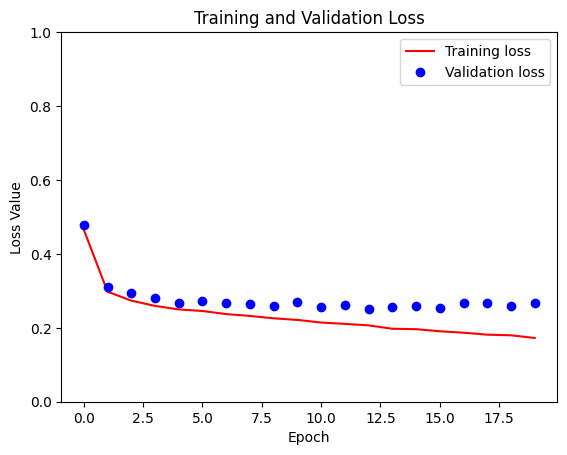

In [ ]:
EPOCHS = 20
VAL_SUBSPLITS = 5 # разобъем процесс валидации на 5 этапов
VALIDATION_STEPS = info.splits['test'].num_examples // BATCH_SIZE // VAL_SUBSPLITS
model_history = model.fit(train_batches, epochs=EPOCHS,
  steps_per_epoch=STEPS_PER_EPOCH,
  validation_steps=VALIDATION_STEPS,
  validation_data=test_batches,
  #callbacks=[DisplayCallback()]
)

loss = model_history.history['loss']
val_loss = model_history.history['val_loss']
plt.plot(model_history.epoch, loss, 'r', label='Training loss')
plt.plot(model_history.epoch, val_loss, 'bo', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss Value')
plt.ylim([0, 1])
plt.legend()
plt.show()


In [ ]:
print(f'точность: {np.mean(model_history.history['val_accuracy'])}')
print(f'потери: {np.mean(model_history.history['val_loss'])}')

точность: 0.8969484061002732
потери: 0.2779235154390335


# Задание № 1: Доработка модели.
1. Доработать нашу модель, включив опциональный dropout, а также тонкую настройку (разморозив коэффициенты).
2. Визуализировать результаты, сравнить с базовой моделью.
3. Сравнить качество и скорость обучения при использовании заморозки
коэффициентов предобученных слоев и без заморозки.

Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 233ms/step - accuracy: 0.7933 - loss: 0.5322 - val_accuracy: 0.8221 - val_loss: 0.6064
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 18s 137ms/step - accuracy: 0.8766 - loss: 0.3281 - val_accuracy: 0.8860 - val_loss: 0.3158
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.8837 - loss: 0.3070 - val_accuracy: 0.8920 - val_loss: 0.2919
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 165ms/step - accuracy: 0.8877 - loss: 0.2958 - val_accuracy: 0.8942 - val_loss: 0.2842
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 142ms/step - accuracy: 0.8912 - loss: 0.2859 - val_accuracy: 0.8900 - val_loss: 0.2903
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 146ms/step - accuracy: 0.8934 - loss: 0.2789 - val_accuracy: 0.8914 - val_loss: 0.2875
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 137ms/step - accuracy: 0.8946 - loss: 0.2754 - val_accuracy: 0.8986 - val_loss: 0.2700
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 140ms/step - accuracy: 0.8953 - loss: 0.2726 - val_accuracy: 

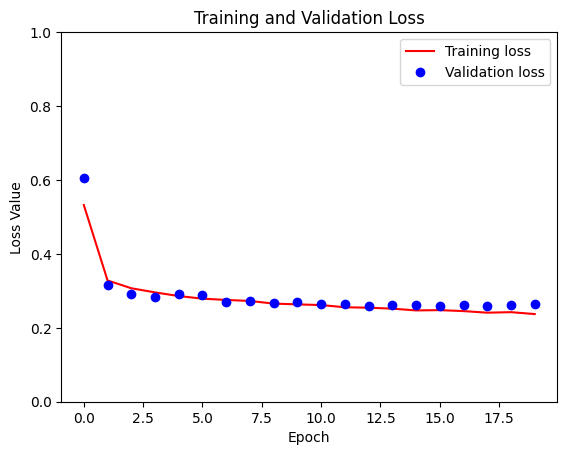

In [ ]:
base_model = tf.keras.applications.MobileNetV2( input_shape=[128, 128, 3],
include_top=False)

layer_names = [
  'block_1_expand_relu',# 64x64 размерность
  'block_3_expand_relu',# 32x32 размерность
  'block_6_expand_relu',# 16x16 размерность
  'block_13_expand_relu', # 8x8 размерность
  'block_16_project',# 4x4 размерность
]

base_model_outputs =[base_model.get_layer(name).output for name in layer_names]
# Создаем энкодерную часть модели (downsampler):
down_stack = tf.keras.Model(inputs=base_model.input,
outputs=base_model_outputs)
down_stack.trainable = False
# замораживаем коэффициенты предобученной модели MobileNet2

def upsample(filters, size, apply_dropout=True):
  initializer = tf.random_normal_initializer(0., 0.02)
  # инициализатор с нормальным распределением (m=0, sigma=0.02)
  result = tf.keras.Sequential()
  result.add(tf.keras.layers.Conv2DTranspose(filters, size, strides=2,
  padding='same',
  kernel_initializer=initializer,
  use_bias=False))
  result.add(tf.keras.layers.BatchNormalization())
  if apply_dropout:
    result.add(tf.keras.layers.Dropout(0.5))
  result.add(tf.keras.layers.ReLU())
  return result

up_stack = [
  upsample(512, 3), # 4x4-> 8x8 после Conv2DTranspose
  upsample(256, 3), # 8x8-> 16x16 ...
  upsample(128, 3), # 16x16-> 32x32 ...
  upsample(64, 3), # 32x32-> 64x64 ...
]

def unet_model(output_channels:int):
  inputs = tf.keras.layers.Input(shape=[128, 128, 3])
  skips = down_stack(inputs)
  x = skips[-1]
  skips = reversed(skips[:-1])
  for up, skip in zip(up_stack, skips):
    x = up(x)
    concat = tf.keras.layers.Concatenate()
    x = concat([x, skip])
  # Итоговый слой должен выдать маску 128x128
  last = tf.keras.layers.Conv2DTranspose(
    filters=output_channels, kernel_size=3, strides=2,
    padding='same') #64x64-> 128x128
  x = last(x)
  return tf.keras.Model(inputs=inputs, outputs=x)

OUTPUT_CLASSES = 3
model = unet_model(output_channels=OUTPUT_CLASSES)
model.compile(optimizer='adam',
  loss=tf.keras.losses.SparseCategoricalCrossentropy(
  from_logits=True),
  # Выходы не нормализованы, поэтому мы используем logits
  metrics=['accuracy'])

tf.keras.utils.plot_model(model, show_shapes=True)

def create_mask(pred_mask):
  pred_mask = tf.math.argmax(pred_mask, axis=-1)
  pred_mask = pred_mask[..., tf.newaxis]
  return pred_mask[0]
def show_predictions(dataset, num=1):
  for image, mask in dataset.take(num):
    pred_mask = model.predict(image)
    display([image[0], mask[0], create_mask(pred_mask)])


class DisplayCallback(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs=None):
      clear_output(wait=True)
      show_predictions(train_batches)
      print ('\nSample Prediction after epoch {}\n'.format(epoch+1))

EPOCHS = 10
VAL_SUBSPLITS = 5 # разобъем процесс валидации на 5 этапов
VALIDATION_STEPS = info.splits['test'].num_examples // BATCH_SIZE // VAL_SUBSPLITS
model_history1 = model.fit(train_batches, epochs=EPOCHS,
  steps_per_epoch=STEPS_PER_EPOCH,
  validation_steps=VALIDATION_STEPS,
  validation_data=test_batches,
  #callbacks=[DisplayCallback()]
                           )

down_stack.trainable = True
EPOCHS = 10
VAL_SUBSPLITS = 5 # разобъем процесс валидации на 5 этапов
VALIDATION_STEPS = info.splits['test'].num_examples // BATCH_SIZE // VAL_SUBSPLITS
model_history2 = model.fit(train_batches, epochs=EPOCHS,
  steps_per_epoch=STEPS_PER_EPOCH,
  validation_steps=VALIDATION_STEPS,
  validation_data=test_batches,
  #callbacks=[DisplayCallback()]
                           )

print(f'точность: {(np.mean(model_history1.history['val_accuracy']) + np.mean(model_history2.history['val_accuracy']))/2}')
print(f'потери: {(np.mean(model_history.history['val_loss']) + np.mean(model_history2.history['val_loss']))/2}')
loss = model_history1.history['loss'] + model_history2.history['loss']
val_loss = model_history1.history['val_loss'] + model_history2.history['val_loss']
plt.plot(model_history.epoch, loss, 'r', label='Training loss')
plt.plot(model_history.epoch, val_loss, 'bo', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss Value')
plt.ylim([0, 1])
plt.legend()
plt.show()

#Задание № 2: Подготовка новых наборов данных.
1. Выбрать один новый тип объекта для сегментации: пожар (1), водоем
(2), свалка (3) в соответсвии с формулой N mod 3 + 1, где N- это номер
в списке группы.
2. Собрать датасет, который будет содержать изображения с нужным объектом (минимум 100 изображений).
3. Подготовить для изображений маски, разметив копии изображений вручную, либо с помощью специальной программы. К примеру, можно воспользовать VIA (VGG Image Annotator).
4. Обучить модель U-net и проверить качество её работы на новом изображении (не входившем в собранный датасет)

#№6->пожар

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from IPython.display import clear_output
import cv2
import numpy as np
import os
import glob
from google.colab.patches import cv2_imshow

Найдено исходных файлов разметки: 25


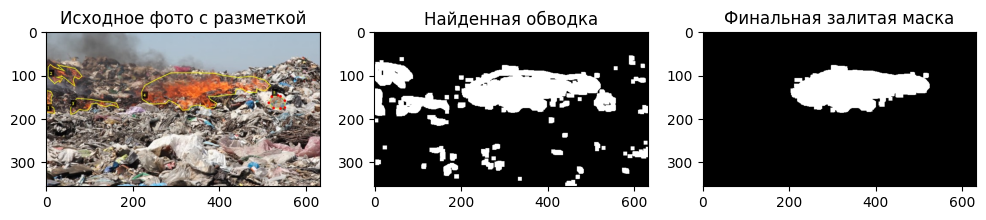

In [ ]:
MASK_SOURCE_DIR = '/content/drive/MyDrive/нейросети миэт/лабораторки по поводу/masks'
MASK_DEST_DIR = '/content/drive/MyDrive/нейросети миэт/лабораторки по поводу/masks_filled'
os.makedirs(MASK_DEST_DIR, exist_ok=True)

mask_paths = glob.glob(os.path.join(MASK_SOURCE_DIR, '*'))
print(f"Найдено исходных файлов разметки: {len(mask_paths)}")

count = 0

for path in mask_paths:
    img = cv2.imread(path)
    if img is None:
        continue

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)


    lower_yellow = np.array([15, 100, 100])
    upper_yellow = np.array([45, 255, 255])
    mask_yellow = cv2.inRange(hsv, lower_yellow, upper_yellow)

    lower_red1 = np.array([0, 100, 100])
    upper_red1 = np.array([10, 255, 255])
    mask_red1 = cv2.inRange(hsv, lower_red1, upper_red1)

    lower_red2 = np.array([160, 100, 100])
    upper_red2 = np.array([180, 255, 255])
    mask_red2 = cv2.inRange(hsv, lower_red2, upper_red2)
    raw_outline = mask_yellow + mask_red1 + mask_red2

    kernel = np.ones((5, 5), np.uint8)
    dilated_outline = cv2.dilate(raw_outline, kernel, iterations=2)

    contours, _ = cv2.findContours(dilated_outline, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    final_mask = np.zeros(img.shape[:2], dtype=np.uint8)

    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        if cv2.contourArea(largest_contour) > 100:
            # Заливаем внутренность контура белым (255)
            cv2.drawContours(final_mask, [largest_contour], -1, 255, thickness=cv2.FILLED)

    filename = os.path.basename(path)
    filename = os.path.splitext(filename)[0] + '.png'
    save_path = os.path.join(MASK_DEST_DIR, filename)

    cv2.imwrite(save_path, final_mask)
    count += 1
    if count == 1:
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 3, 1)
        plt.title("Исходное фото с разметкой")
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.subplot(1, 3, 2)
        plt.title("Найденная обводка")
        plt.imshow(dilated_outline, cmap='gray')
        plt.subplot(1, 3, 3)
        plt.title("Финальная залитая маска")
        plt.imshow(final_mask, cmap='gray')
        plt.show()


In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 16
BUFFER_SIZE = 25
EPOCHS = 30

DATA_DIR = '/content/drive/MyDrive/нейросети миэт/лабораторки по поводу'
IMG_DIR = os.path.join(DATA_DIR, 'images')
MASK_DIR = os.path.join(DATA_DIR, 'masks_filled')

image_paths = sorted(glob.glob(os.path.join(IMG_DIR, '*')))
mask_paths = sorted(glob.glob(os.path.join(MASK_DIR, '*')))

# обучение и тест (90% на 10%)
train_img_paths, test_img_paths, train_mask_paths, test_mask_paths = train_test_split(
    image_paths, mask_paths, test_size=0.1, random_state=42
)

In [ ]:
def read_image(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0  # Нормализация [0, 1]
    return img

def read_mask(mask_path):
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_jpeg(mask, channels=1)
    mask = tf.image.resize(mask, (IMG_SIZE, IMG_SIZE), method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)

    # обработка маски:
    # если маска 0-255, переводим в 0 и 1.
    # значения > 128 считаем за класс 1 (объект), остальные - 0 (фон)
    mask = tf.cast(mask > 128, tf.int32)
    return mask

def load_data(image_path, mask_path):
    img = read_image(image_path)
    mask = read_mask(mask_path)
    return img, mask

# Создание tf.data.Dataset
train_dataset = tf.data.Dataset.from_tensor_slices((train_img_paths, train_mask_paths))
train_dataset = train_dataset.map(load_data, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat().prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_img_paths, test_mask_paths))
test_dataset = test_dataset.map(load_data, num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(BATCH_SIZE)

In [ ]:
class Augment(tf.keras.layers.Layer):
  def __init__(self, seed=42):
    super().__init__()
    self.augment_inputs = tf.keras.layers.RandomFlip(mode="horizontal", seed=seed)
    self.augment_labels = tf.keras.layers.RandomFlip(mode="horizontal", seed=seed)
  def call(self, inputs, labels):
    inputs = self.augment_inputs(inputs)
    labels = self.augment_labels(labels)
    return inputs, labels

train_dataset = train_dataset.map(Augment())

base_model = tf.keras.applications.MobileNetV2(input_shape=[IMG_SIZE, IMG_SIZE, 3], include_top=False)

layer_names = [
  'block_1_expand_relu',   # 64x64
  'block_3_expand_relu',   # 32x32
  'block_6_expand_relu',   # 16x16
  'block_13_expand_relu',  # 8x8
  'block_16_project',      # 4x4
]

base_model_outputs = [base_model.get_layer(name).output for name in layer_names]
down_stack = tf.keras.Model(inputs=base_model.input, outputs=base_model_outputs)
down_stack.trainable = False

def upsample(filters, size, apply_dropout=False):
  initializer = tf.random_normal_initializer(0., 0.02)
  result = tf.keras.Sequential()
  result.add(tf.keras.layers.Conv2DTranspose(filters, size, strides=2,
                                             padding='same',
                                             kernel_initializer=initializer,
                                             use_bias=False))
  result.add(tf.keras.layers.BatchNormalization())
  if apply_dropout:
      result.add(tf.keras.layers.Dropout(0.5))
  result.add(tf.keras.layers.ReLU())
  return result

up_stack = [
  upsample(512, 3),
  upsample(256, 3),
  upsample(128, 3),
  upsample(64, 3),
]

def unet_model(output_channels:int):
  inputs = tf.keras.layers.Input(shape=[IMG_SIZE, IMG_SIZE, 3])
  skips = down_stack(inputs)
  x = skips[-1]
  skips = reversed(skips[:-1])

  for up, skip in zip(up_stack, skips):
    x = up(x)
    concat = tf.keras.layers.Concatenate()
    x = concat([x, skip])

  last = tf.keras.layers.Conv2DTranspose(
    filters=output_channels, kernel_size=3, strides=2,
    padding='same') # 64x64 -> 128x128
  x = last(x)
  return tf.keras.Model(inputs=inputs, outputs=x)

In [ ]:
OUTPUT_CLASSES = 3
model = unet_model(output_channels=OUTPUT_CLASSES)
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

# Визуализация результатов во время обучения
def create_mask(pred_mask):
  pred_mask = tf.math.argmax(pred_mask, axis=-1)
  pred_mask = pred_mask[..., tf.newaxis]
  return pred_mask[0]

def display(display_list):
  plt.figure(figsize=(15, 15))
  title = ['Input Image', 'True Mask', 'Predicted Mask']
  for i in range(len(display_list)):
    plt.subplot(1, len(display_list), i+1)
    plt.title(title[i])
    plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
    plt.axis('off')
  plt.show()

def show_predictions(dataset=None, num=1):
  if dataset:
    for image, mask in dataset.take(num):
      pred_mask = model.predict(image)
      display([image[0], mask[0], create_mask(pred_mask)])
  else:
    display([sample_image, sample_mask,
             create_mask(model.predict(sample_image[tf.newaxis, ...]))])

class DisplayCallback(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs=None):
    clear_output(wait=True)
    show_predictions(test_dataset)
    print ('\nSample Prediction after epoch {}\n'.format(epoch+1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


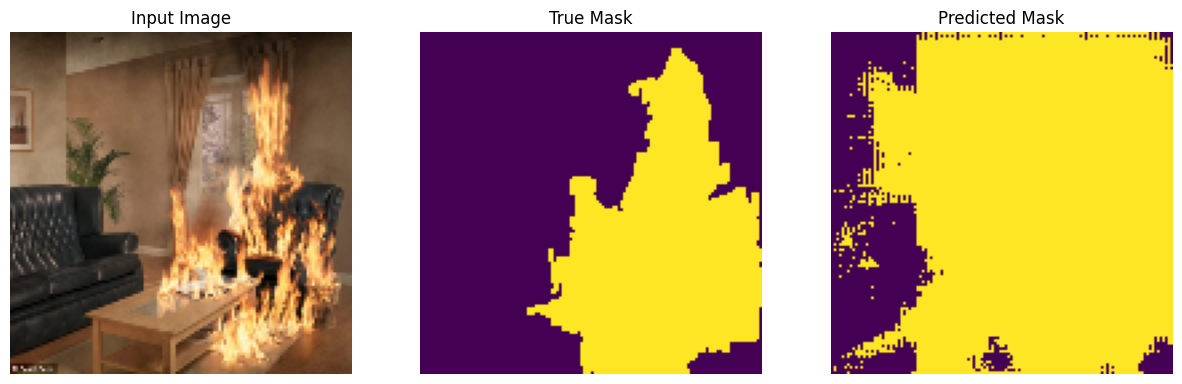


Sample Prediction after epoch 30

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step - accuracy: 0.9295 - loss: 0.2430 - val_accuracy: 0.4632 - val_loss: 1.8586


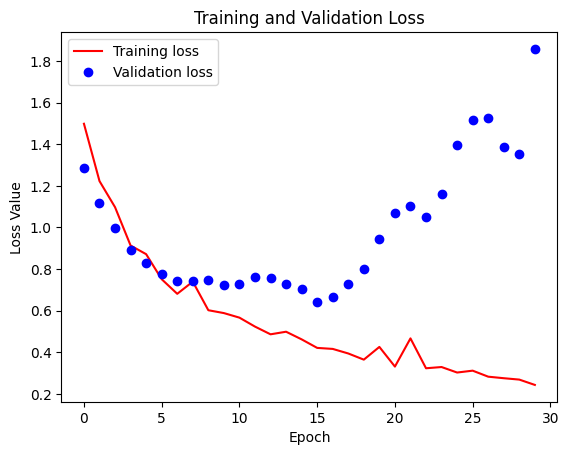

In [ ]:
STEPS_PER_EPOCH = len(train_img_paths) // BATCH_SIZE
VALIDATION_STEPS = len(test_img_paths) // BATCH_SIZE

if STEPS_PER_EPOCH == 0: STEPS_PER_EPOCH = 1
if VALIDATION_STEPS == 0: VALIDATION_STEPS = 1

model_history = model.fit(train_dataset,
                          epochs=EPOCHS,
                          steps_per_epoch=STEPS_PER_EPOCH,
                          validation_steps=VALIDATION_STEPS,
                          validation_data=test_dataset,
                          callbacks=[DisplayCallback()]
                          )

# График потерь
loss = model_history.history['loss']
val_loss = model_history.history['val_loss']

plt.figure()
plt.plot(model_history.epoch, loss, 'r', label='Training loss')
plt.plot(model_history.epoch, val_loss, 'bo', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss Value')
plt.legend()
plt.show()

In [ ]:
print(f'точность: {np.mean(model_history.history['val_accuracy'])}')
print(f'потери: {np.mean(model_history.history['val_loss'])}')

точность: 0.5645623147487641
потери: 0.9918611029783885
